| **Inicio**         | **Siguiente 2**                                    |
| ------------------  | -------------------------------------------------- |
| [🏠](../README.md)  | [⏩](./5_2_Sistemas_dinamicos.ipynb) |

# 1. ¿Qué es una ODE?

**ODE = Ordinary Differential Equation**, o **ecuación diferencial ordinaria**.

Una ODE relaciona una función desconocida con sus derivadas respecto a **una sola variable independiente**.

Por ejemplo:

$$
\frac{dy}{dt}=3y
$$

Aquí:

* $(t)$: variable independiente, normalmente tiempo.
* $(y(t))$: variable que queremos encontrar.
* $(dy/dt)$: velocidad de cambio de $(y)$.

La pregunta fundamental es:

> **¿Qué función $(y(t))$ tiene una derivada igual a $(3y)$?**

La solución es

$$
y(t)=Ce^{3t}
$$

porque

$$
\frac{d}{dt}Ce^{3t}=3Ce^{3t}=3y.
$$

# 2. ¿Por qué las ODE son tan importantes en SciML?


Muchísimos sistemas físicos pueden escribirse como:

$$
\frac{d\mathbf{x}}{dt}=f(t,\mathbf{x},\theta)
$$

donde:

* $(\mathbf{x})$: estado del sistema.
* $(t)$: tiempo.
* $(\theta)$: parámetros.
* $(f)$: leyes físicas.

Por ejemplo, para un automóvil:

$$
\mathbf{x}=
\begin{bmatrix}
posición\\
velocidad
\end{bmatrix}
$$

y

$$
\frac{d\mathbf{x}}{dt}
=
\begin{bmatrix}
velocidad\\
aceleración
\end{bmatrix}.
$$

En SciML muchas veces queremos aprender alguno de estos elementos:

$$
\frac{d\mathbf{x}}{dt}=f_\theta(t,\mathbf{x})
$$

donde $(f_\theta)$ puede ser una **red neuronal**.

Esto lleva directamente a:

* Neural ODEs
* Physics-Informed Neural Networks
* Neural SDEs
* sistemas dinámicos aprendidos
* control
* identificación de sistemas
* modelos híbridos físico + ML.

# 3. Ecuaciones de primer orden

Una ODE de primer orden tiene como máximo:

$$
\frac{dy}{dt}
$$

y no aparece $(y'')$, $(y''')$, etc.

La forma general es:

$$
F(t,y,y')=0.
$$

Muchas veces podemos escribirla como:

$$
\boxed{y'=f(t,y)}
$$

Esta forma es especialmente importante en SciML.

# 4. Problema de valor inicial — IVP

Normalmente una ODE viene acompañada de una condición inicial:

$$
y'=f(t,y)
$$

$$
y(t_0)=y_0.
$$

Por ejemplo:

$$
y'=2y
$$

$$
y(0)=3.
$$

La condición inicial determina cuál de las infinitas soluciones queremos.

Sin ella:

$$
y=Ce^{2t}
$$

tenemos infinitas soluciones.

Con:

$$
y(0)=3
$$

obtenemos:

$$
3=C
$$

por tanto:

$$
\boxed{y(t)=3e^{2t}}
$$

# 5. Ecuaciones separables

Una ODE es **separable** cuando podemos escribir:

$$
\frac{dy}{dt}=g(t)h(y).
$$

Podemos separar:

$$
\frac{1}{h(y)}dy=g(t)dt.
$$

Después integramos:

$$
\int \frac{1}{h(y)}dy
=
\int g(t)dt.
$$

# 6. Ejemplo difícil: crecimiento logístico

Este es uno de los modelos más importantes de las ODE.

Supongamos:

$$
\boxed{
\frac{dP}{dt}
=
rP\left(1-\frac{P}{K}\right)
}
$$

donde:

* $P(t)$: población.
* $(r)$: tasa de crecimiento.
* $(K)$: capacidad máxima del ambiente.

Este modelo aparece en:

* población humana,
* bacterias,
* propagación limitada,
* adopción de productos,
* crecimiento de recursos,
* modelos ecológicos.

## 6.1 Separando

Tenemos:

$$
\frac{dP}{dt}
=
rP\left(1-\frac{P}{K}\right)
$$

y:

$$
1-\frac PK
=
\frac{K-P}{K}.
$$

Entonces:

$$
\frac{dP}{dt}
=
\frac rK P(K-P).
$$

Separando:

$$
\frac{K}{P(K-P)}dP=r\,dt.
$$

Usamos fracciones parciales:

$$
\frac{K}{P(K-P)}
=
\frac1P+\frac1{K-P}.
$$

Entonces:

$$
\int
\left(
\frac1P+\frac1{K-P}
\right)dP
=
\int rdt.
$$

Obtenemos:

$$
\ln|P|-\ln|K-P|=rt+C.
$$

Por propiedades logarítmicas:

$$
\ln
\left|
\frac{P}{K-P}
\right|
=rt+C.
$$

Finalmente:

$$
\boxed{
P(t)=
\frac{K}
{1+Ae^{-rt}}
}
$$

# 7. Ejemplo real: crecimiento de una población

Supongamos:

$$
K=1000
$$

$$
r=0.8
$$

$$
P(0)=50.
$$

Entonces:

$$
P(t)=
\frac{1000}{1+Ae^{-0.8t}}.
$$

Usamos:

$$
50=\frac{1000}{1+A}
$$

por lo que:

$$
1+A=20
$$

$$
A=19.
$$

Entonces:

$$
\boxed{
P(t)=
\frac{1000}{1+19e^{-0.8t}}
}
$$

Observa algo importante.

Al principio:

$$
P\ll K
$$

y aproximadamente:

$$
P'\approx rP.
$$

Por tanto el crecimiento parece exponencial.

Pero cuando:

$$
P\rightarrow K
$$

tenemos:

$$
P'\rightarrow0.
$$

## Gráfica Python

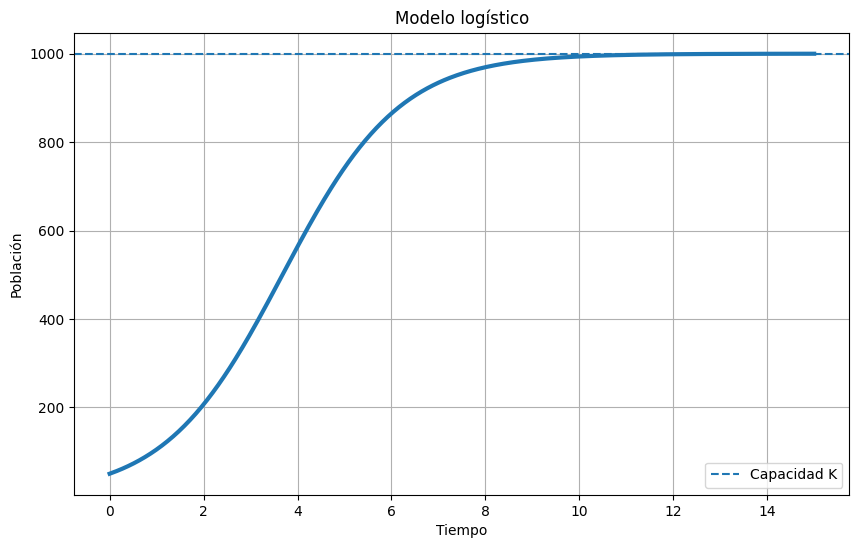

In [1]:
import numpy as np
import matplotlib.pyplot as plt

K = 1000
r = 0.8
A = 19

t = np.linspace(0, 15, 500)

P = K / (1 + A * np.exp(-r * t))

plt.figure(figsize=(10, 6))

plt.plot(t, P, linewidth=3)

plt.axhline(
    K,
    linestyle="--",
    label="Capacidad K"
)

plt.xlabel("Tiempo")
plt.ylabel("Población")
plt.title("Modelo logístico")

plt.grid(True)
plt.legend()

plt.show()

# 8. Interpretación geométrica

La ecuación

$$
P'=rP\left(1-\frac PK\right)
$$

nos dice directamente la pendiente.

Si:

$$
0<P<K
$$

entonces:

$$
P'>0.
$$

La población aumenta.

Si:

$$
P>K
$$

entonces:

$$
P'<0.
$$

La población disminuye.

Si:

$$
P=K
$$

entonces:

$$
P'=0.
$$

Por eso $(K)$ es un equilibrio.

# 9. Ecuaciones lineales de primer orden

Una ecuación lineal tiene la forma:

$$
\boxed{
y'+P(t)y=Q(t)
}
$$

El método principal es el **factor integrante**.

Definimos:

$$
\boxed{
\mu(t)=e^{\int P(t)dt}
}
$$

Multiplicamos toda la ecuación:

$$
\mu y'+\mu Py=\mu Q.
$$

El lado izquierdo se convierte en:

$$
\frac{d}{dt}[\mu y].
$$

Por tanto:

$$
\frac{d}{dt}[\mu y]
=
\mu Q.
$$

Integramos.

# 10. Ejemplo difícil: enfriamiento con ambiente variable

Consideremos:

$$
\boxed{
T'+0.15T
=
0.15(20+10\sin t)
}
$$

Interpretación:

* $T(t)$: temperatura de un objeto.
* $(20+10\sin t)$: temperatura ambiental.
* $(0.15)$: constante de transferencia térmica.

Supongamos:

$$
T(0)=80.
$$

El factor integrante es:

$$
\mu(t)=e^{0.15t}.
$$

Entonces:

$$
\frac{d}{dt}
\left(
e^{0.15t}T
\right)
=
0.15e^{0.15t}(20+10\sin t).
$$

La solución se puede obtener analíticamente o numéricamente.

Para SciML, la segunda opción es extremadamente importante.

## Python usando SciPy

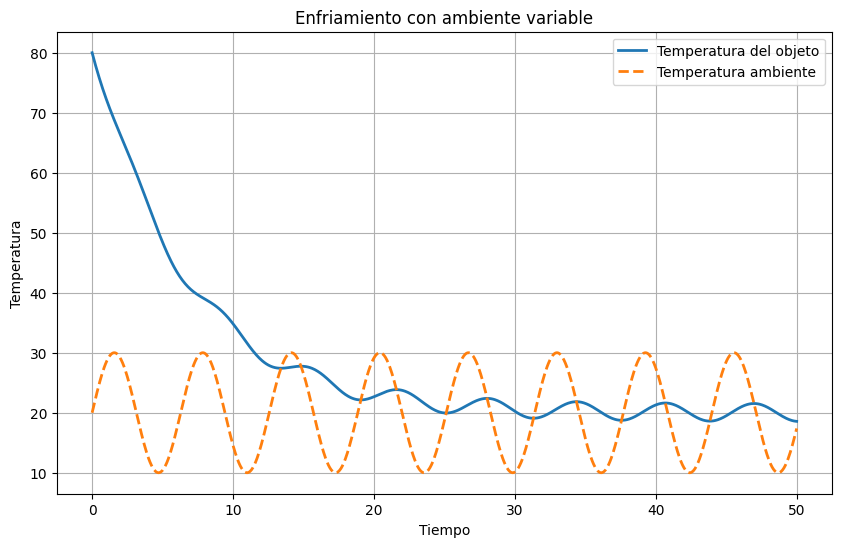

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def temperature(t, T):
    ambient = 20 + 10*np.sin(t)
    return 0.15 * (ambient - T[0])

t_span = (0, 50)

T0 = [80]

solution = solve_ivp(
    temperature,
    t_span,
    T0,
    dense_output=True,
    max_step=0.05
)

t = np.linspace(0, 50, 1000)

T = solution.sol(t)[0]

ambient = 20 + 10*np.sin(t)

plt.figure(figsize=(10, 6))

plt.plot(
    t,
    T,
    linewidth=2,
    label="Temperatura del objeto"
)

plt.plot(
    t,
    ambient,
    linestyle="--",
    linewidth=2,
    label="Temperatura ambiente"
)

plt.xlabel("Tiempo")
plt.ylabel("Temperatura")
plt.title("Enfriamiento con ambiente variable")

plt.grid(True)
plt.legend()

plt.show()

Esto es mucho más cercano a cómo se trabajan ODE en SciML que resolver siempre todo simbólicamente.

# 11. Ecuaciones exactas

Consideremos:

$$
M(x,y)dx+N(x,y)dy=0.
$$

La ecuación es **exacta** si existe una función:

$$
\Psi(x,y)
$$

tal que:

$$
\frac{\partial\Psi}{\partial x}=M
$$

y

$$
\frac{\partial\Psi}{\partial y}=N.
$$

La condición:

$$
\boxed{
\frac{\partial M}{\partial y}
=
\frac{\partial N}{\partial x}
}
$$

indica que la ecuación es exacta, bajo las condiciones usuales de continuidad.

# 12. Ejemplo difícil de ecuación exacta

Consideremos:

$$
\boxed{
(2xy+3x^2)dx
+
(x^2+4y^3)dy
=0
}
$$

Tenemos:

$$
M=2xy+3x^2
$$

$$
N=x^2+4y^3.
$$

Calculamos:

$$
M_y=2x
$$

y:

$$
N_x=2x.
$$

Por tanto:

$$
M_y=N_x.
$$

Es exacta.

Buscamos:

$$
\Psi_x=M.
$$

Integramos respecto a $(x)$:

$$
\Psi=
x^2y+x^3+g(y).
$$

Ahora derivamos respecto a $(y)$:

$$
\Psi_y=x^2+g'(y).
$$

Esto debe ser $(N)$:

$$
x^2+g'(y)=x^2+4y^3.
$$

Por tanto:

$$
g'(y)=4y^3.
$$

Integrando:

$$
g(y)=y^4.
$$

Así:

$$
\boxed{
\Psi(x,y)=x^2y+x^3+y^4
}
$$

y la solución implícita es:

$$
\boxed{
x^2y+x^3+y^4=C
}
$$

# 13. Gráfica de una solución exacta

Podemos visualizar las curvas:

$$
x^2y+x^3+y^4=C.
$$

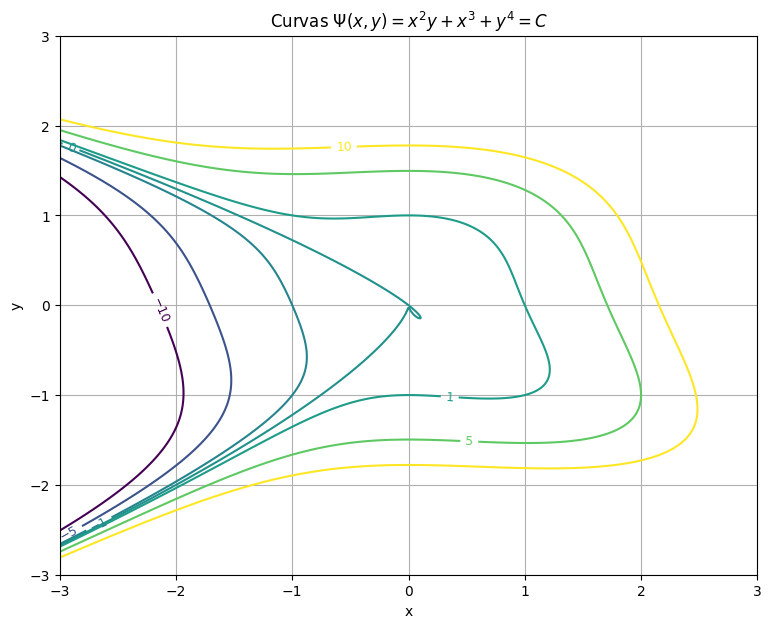

In [3]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-3, 3, 500)
y = np.linspace(-3, 3, 500)

X, Y = np.meshgrid(x, y)

Psi = X**2 * Y + X**3 + Y**4

plt.figure(figsize=(9, 7))

levels = [-10, -5, -1, 0, 1, 5, 10]

contours = plt.contour(
    X,
    Y,
    Psi,
    levels=levels
)

plt.clabel(contours, inline=True, fontsize=9)

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    r"Curvas $\Psi(x,y)=x^2y+x^3+y^4=C$"
)

plt.grid(True)

plt.show()

Estas curvas son **curvas solución**.

# 14. Sistemas de ODE

Aquí entramos en una parte fundamental para SciML.

En lugar de:

$$
y'=f(t,y)
$$

tenemos:

$$
\boxed{
\frac{d\mathbf{x}}{dt}
=
\mathbf{f}(t,\mathbf{x})
}
$$

donde:

$$
\mathbf{x}
=
\begin{bmatrix}
x_1\\
x_2\\
\vdots\\
x_n
\end{bmatrix}.
$$

# 15. Ejemplo: depredador-presa

Un modelo clásico es Lotka-Volterra:

$$
\boxed{
\frac{dx}{dt}
=
\alpha x-\beta xy
}
$$

$$
\boxed{
\frac{dy}{dt}
=
\delta xy-\gamma y
}
$$

donde:

* $(x)$: presas.
* $(y)$: depredadores.

Interpretación:

### Presas

$$
\alpha x
$$

crecimiento natural.

$$
-\beta xy
$$

pérdida por depredación.

### Depredadores

$$
\delta xy
$$

aumento debido a alimento.

$$
-\gamma y
$$

mortalidad natural.

# 16. Resolver el sistema con SciPy

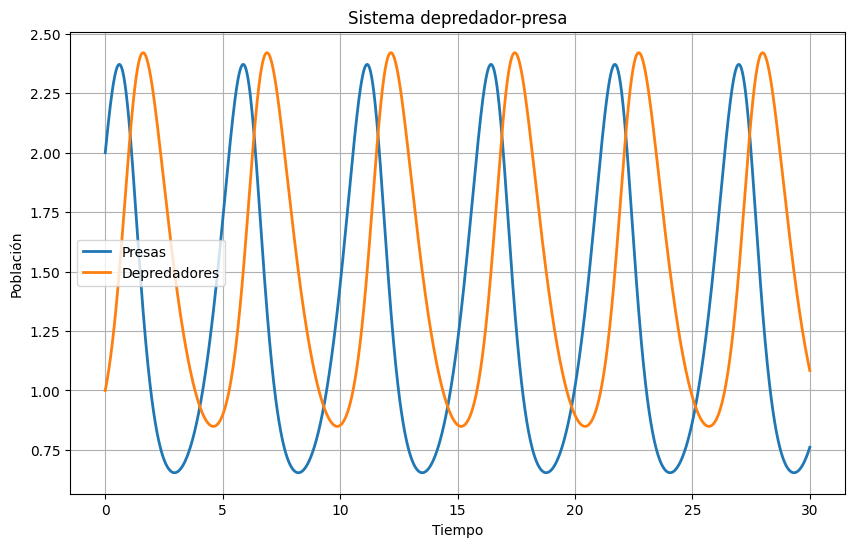

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

alpha = 1.5
beta = 1.0
delta = 0.75
gamma = 1.0

def lotka_volterra(t, z):

    x, y = z

    dxdt = alpha*x - beta*x*y
    dydt = delta*x*y - gamma*y

    return [dxdt, dydt]

t_span = (0, 30)

initial_condition = [2, 1]

solution = solve_ivp(
    lotka_volterra,
    t_span,
    initial_condition,
    dense_output=True,
    max_step=0.02
)

t = np.linspace(0, 30, 2000)

x, y = solution.sol(t)

plt.figure(figsize=(10, 6))

plt.plot(
    t,
    x,
    label="Presas",
    linewidth=2
)

plt.plot(
    t,
    y,
    label="Depredadores",
    linewidth=2
)

plt.xlabel("Tiempo")
plt.ylabel("Población")

plt.title("Sistema depredador-presa")

plt.grid(True)
plt.legend()

plt.show()

# 17. Pero en SciML hay otra gráfica aún más importante

En lugar de:

$$
x(t),y(t)
$$

podemos representar:

$$
y
$$

contra

$$
x.
$$

Esto se llama **phase portrait**.

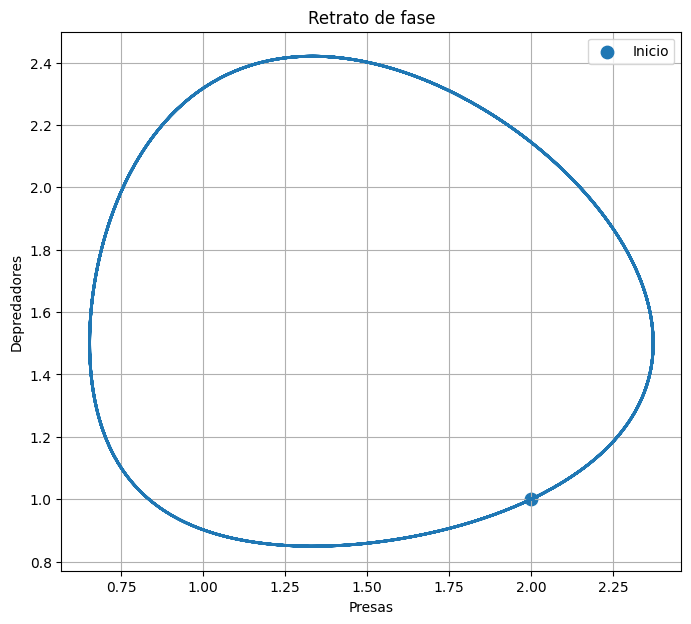

In [5]:
plt.figure(figsize=(8, 7))

plt.plot(
    x,
    y,
    linewidth=2
)

plt.scatter(
    x[0],
    y[0],
    s=80,
    label="Inicio"
)

plt.xlabel("Presas")
plt.ylabel("Depredadores")

plt.title("Retrato de fase")

plt.grid(True)
plt.legend()

plt.show()

Esta gráfica nos permite estudiar la **dinámica del sistema**.

Esto será extremadamente importante cuando estudies:

* sistemas dinámicos,
* estabilidad,
* caos,
* control,
* Neural ODEs.

# 18. Segundo orden

Una ODE de segundo orden contiene:

$$
y''
$$

por ejemplo:

$$
\boxed{
y''+cy'+ky=F(t)
}
$$

Esta ecuación aparece continuamente en física.

Un ejemplo clásico:

$$
\boxed{
m x''+cx'+kx=F(t)
}
$$

Es el sistema **masa-resorte-amortiguador**.

# 19. Vida real: suspensión de un automóvil

Podemos pensar en:

* $(m)$: masa.
* $(c)$: amortiguamiento.
* $(k)$: rigidez del resorte.
* $(x(t))$: desplazamiento.

La ecuación:

$$
mx''+cx'+kx=F(t).
$$

Por ejemplo:

$$
m=1000
$$

$$
c=1500
$$

$$
k=20000.
$$

Supongamos que el automóvil recibe una fuerza:

$$
F(t)=5000\sin(3t).
$$

Entonces:

$$
1000x''+1500x'+20000x
=
5000\sin(3t).
$$

# 20. Convertir una ODE de segundo orden en sistema de primer orden

Esto es crucial.

Definimos:

$$
x_1=x
$$

$$
x_2=x'.
$$

Entonces:

$$
x_1'=x_2.
$$

Y:

$$
x_2'
=
\frac{F(t)-cx_2-kx_1}{m}.
$$

Así tenemos:

$$
\boxed{
\begin{cases}
x_1'=x_2\\
x_2'=\frac{F(t)-cx_2-kx_1}{m}
\end{cases}
}
$$

Esto permite utilizar `solve_ivp`.

# 21. Python

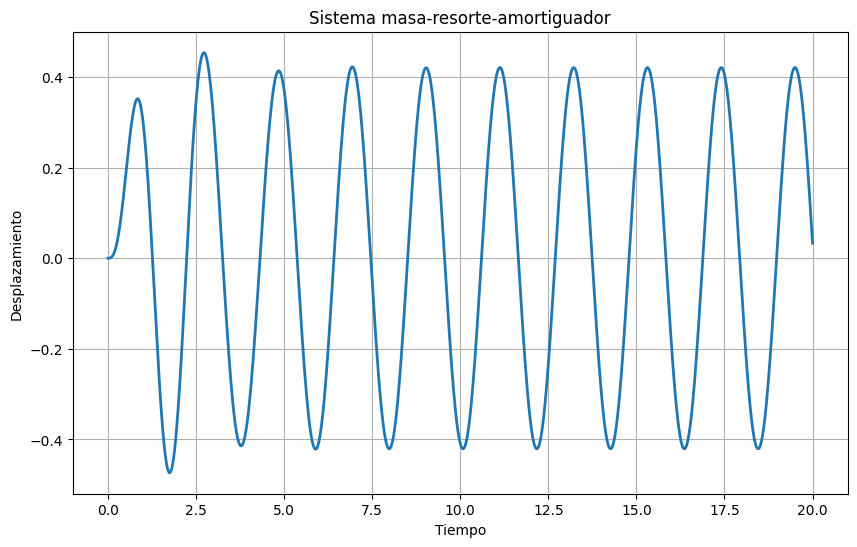

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

m = 1000
c = 1500
k = 20000

def F(t):
    return 5000 * np.sin(3*t)

def suspension(t, z):

    x = z[0]
    v = z[1]

    dxdt = v

    dvdt = (
        F(t)
        - c*v
        - k*x
    ) / m

    return [dxdt, dvdt]

t_span = (0, 20)

initial_condition = [0, 0]

solution = solve_ivp(
    suspension,
    t_span,
    initial_condition,
    dense_output=True,
    max_step=0.01
)

t = np.linspace(0, 20, 3000)

x, v = solution.sol(t)

plt.figure(figsize=(10, 6))

plt.plot(
    t,
    x,
    linewidth=2
)

plt.xlabel("Tiempo")
plt.ylabel("Desplazamiento")

plt.title(
    "Sistema masa-resorte-amortiguador"
)

plt.grid(True)

plt.show()

# 22. ¿Qué significa físicamente?

Tenemos:

$$
mx''
$$

que representa la inercia.

Tenemos:

$$
cx'
$$

que representa disipación.

Tenemos:

$$
kx
$$

que representa la fuerza restauradora.

Entonces:

$$
\boxed{
\text{inercia}
+
\text{amortiguamiento}
+
\text{resorte}
=
\text{fuerza externa}
}
$$

Esta estructura aparece en muchísimos sistemas.

# 23. Ecuaciones no lineales

Aquí comienza una parte especialmente importante para SciML.

Una ODE lineal tiene algo como:

$$
y'+a(t)y=b(t).
$$

Pero una ecuación como:

$$
\boxed{
y'=y^2-y
}
$$

es no lineal.

¿Por qué?

Porque aparece:

$$
y^2.
$$

Otros ejemplos de no linealidad:

$$
\sin(y)
$$

$$
e^y
$$

$$
yy'
$$

$$
y^3.
$$

# 24. Ejemplo difícil: ecuación de Riccati

Consideremos:

$$
\boxed{
y'=y^2-2y+1
}
$$

Esto puede escribirse:

$$
y'=(y-1)^2.
$$

Separando:

$$
\frac{dy}{(y-1)^2}=dt.
$$

Integramos:

$$
-\frac{1}{y-1}=t+C.
$$

Por tanto:

$$
y-1=-\frac1{t+C}.
$$

Así:

$$
\boxed{
y(t)=1-\frac1{t+C}
}
$$

Observa algo muy importante:

La solución puede **explotar en tiempo finito**.

Si:

$$
C=1
$$

entonces:

$$
y(t)=1-\frac1{t+1}.
$$

Tiene una singularidad en:

$$
t=-1.
$$

# 25. Ejemplo no lineal mucho más interesante: péndulo

Una aplicación real fantástica es el péndulo.

La ecuación exacta es:

$$
\boxed{
\theta''+
\frac{g}{L}\sin\theta=0
}
$$

Observa:

$$
\sin\theta.
$$

Por eso es **no lineal**.

Si usamos la aproximación:

$$
\sin\theta\approx\theta
$$

obtenemos:

$$
\theta''
+
\frac gL\theta=0,
$$

que es lineal.

Pero para ángulos grandes, esa aproximación puede ser mala.

# 26. Péndulo: solución numérica

Definimos:

$$
x_1=\theta
$$

$$
x_2=\theta'.
$$

Entonces:

$$
x_1'=x_2
$$

$$
x_2'
=
-\frac gL\sin(x_1).
$$

Python:

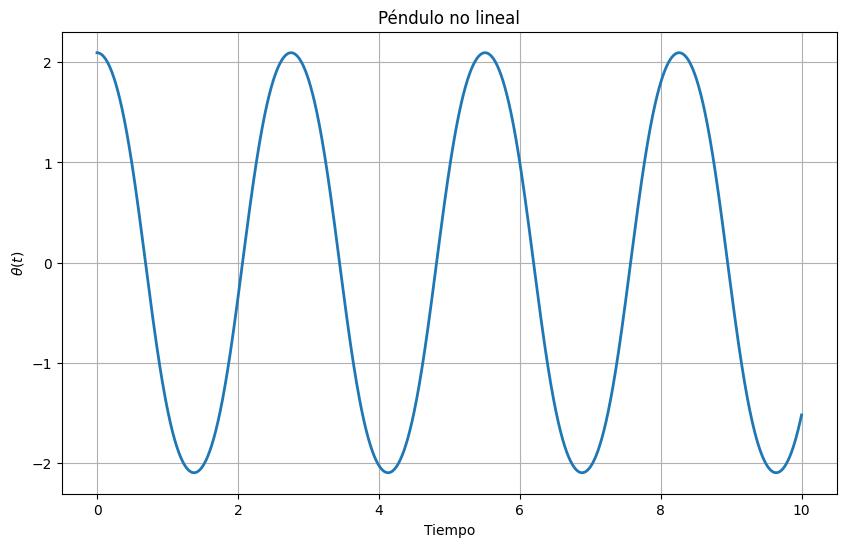

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

g = 9.81
L = 1.0

def pendulum(t, z):

    theta = z[0]
    omega = z[1]

    dtheta = omega

    domega = -(g/L) * np.sin(theta)

    return [dtheta, domega]

theta0 = np.deg2rad(120)
omega0 = 0

solution = solve_ivp(
    pendulum,
    (0, 10),
    [theta0, omega0],
    dense_output=True,
    max_step=0.005
)

t = np.linspace(0, 10, 2000)

theta, omega = solution.sol(t)

plt.figure(figsize=(10, 6))

plt.plot(
    t,
    theta,
    linewidth=2
)

plt.xlabel("Tiempo")
plt.ylabel(r"$\theta(t)$")

plt.title("Péndulo no lineal")

plt.grid(True)

plt.show()

# 27. Comparar péndulo lineal vs no lineal

Esto es particularmente útil para entender SciML.

Modelo exacto:

$$
\theta''
+
\frac gL\sin\theta=0.
$$

Modelo aproximado:

$$
\theta''
+
\frac gL\theta=0.
$$

Podemos resolver ambos.

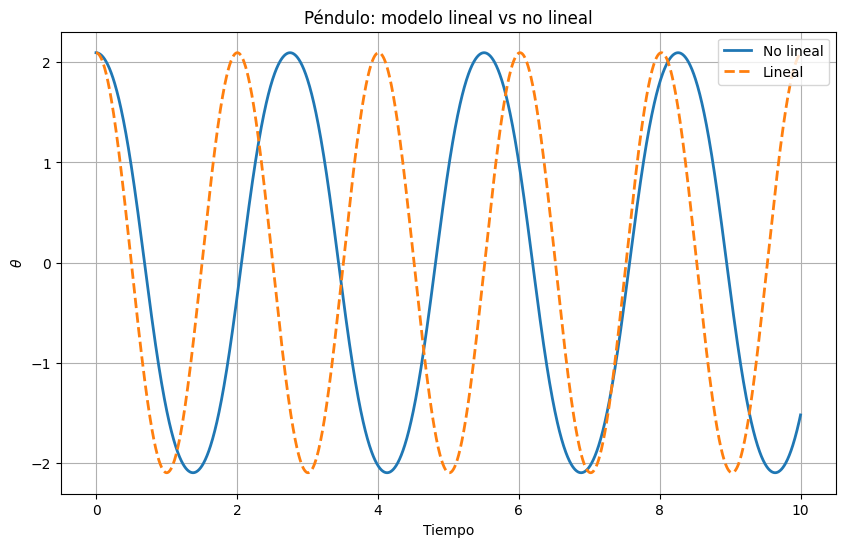

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

g = 9.81
L = 1.0

theta0 = np.deg2rad(120)
omega0 = 0

def nonlinear(t, z):

    theta, omega = z

    return [
        omega,
        -(g/L)*np.sin(theta)
    ]

def linear(t, z):

    theta, omega = z

    return [
        omega,
        -(g/L)*theta
    ]

t_span = (0, 10)

sol_nonlinear = solve_ivp(
    nonlinear,
    t_span,
    [theta0, omega0],
    dense_output=True,
    max_step=0.005
)

sol_linear = solve_ivp(
    linear,
    t_span,
    [theta0, omega0],
    dense_output=True,
    max_step=0.005
)

t = np.linspace(0, 10, 2000)

theta_nonlinear = sol_nonlinear.sol(t)[0]
theta_linear = sol_linear.sol(t)[0]

plt.figure(figsize=(10, 6))

plt.plot(
    t,
    theta_nonlinear,
    linewidth=2,
    label="No lineal"
)

plt.plot(
    t,
    theta_linear,
    "--",
    linewidth=2,
    label="Lineal"
)

plt.xlabel("Tiempo")
plt.ylabel(r"$\theta$")

plt.title(
    "Péndulo: modelo lineal vs no lineal"
)

plt.grid(True)
plt.legend()

plt.show()

Para un ángulo inicial pequeño, las soluciones se parecen mucho.

Para:

$$
\theta_0=120^\circ
$$

la diferencia empieza a ser importante.

# 28. Un concepto fundamental: campo de pendientes

Para una ODE:

$$
y'=f(t,y)
$$

podemos dibujar pequeños segmentos con pendiente:

$$
f(t,y).
$$

Esto se llama **direction field** o **slope field**.

Por ejemplo:

$$
y'=y(1-y).
$$

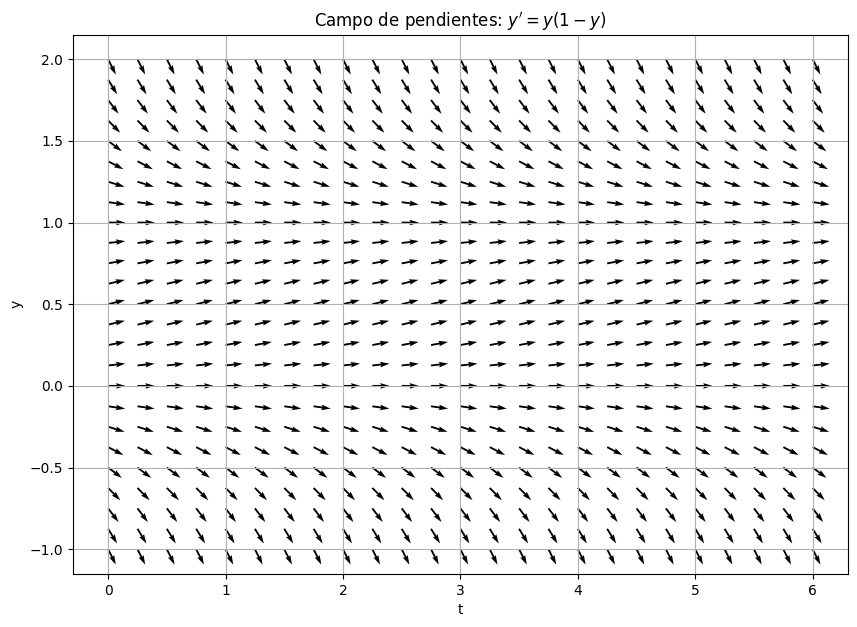

In [9]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 6, 25)
y = np.linspace(-1, 2, 25)

T, Y = np.meshgrid(t, y)

DY = Y * (1 - Y)
DT = np.ones_like(DY)

norm = np.sqrt(DT**2 + DY**2)

DT = DT / norm
DY = DY / norm

plt.figure(figsize=(10, 7))

plt.quiver(
    T,
    Y,
    DT,
    DY
)

plt.xlabel("t")
plt.ylabel("y")

plt.title(
    r"Campo de pendientes: $y'=y(1-y)$"
)

plt.grid(True)

plt.show()

Este gráfico permite ver **cómo evolucionaría cualquier condición inicial**.

# 29. Podemos superponer soluciones

Esto es aún mejor.

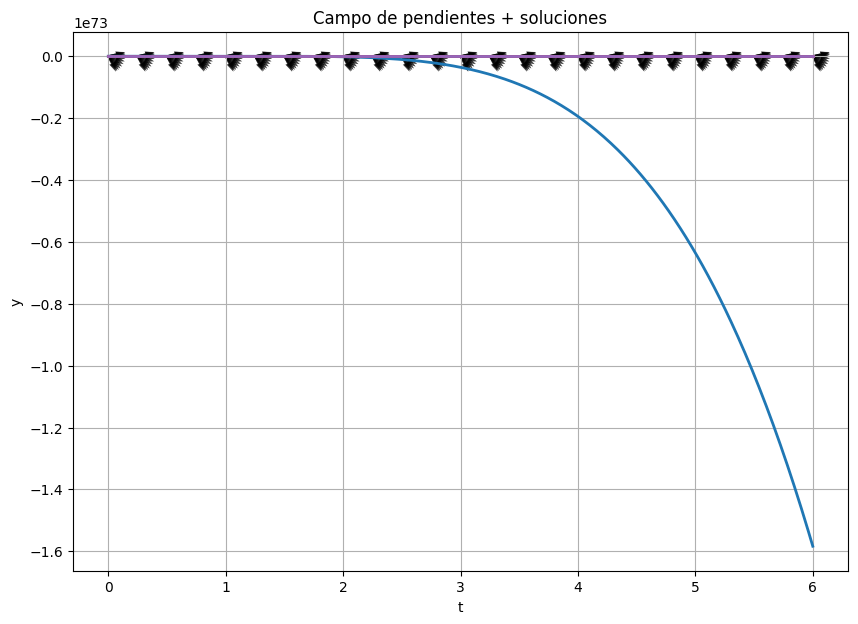

In [10]:
from scipy.integrate import solve_ivp

def logistic(t, y):
    return y * (1 - y)

plt.figure(figsize=(10, 7))

plt.quiver(
    T,
    Y,
    DT,
    DY,
    alpha=0.5
)

initial_conditions = [
    -0.5,
    0.2,
    0.5,
    1.2,
    1.8
]

for y0 in initial_conditions:

    sol = solve_ivp(
        logistic,
        (0, 6),
        [y0],
        dense_output=True
    )

    tt = np.linspace(0, 6, 500)

    yy = sol.sol(tt)[0]

    plt.plot(
        tt,
        yy,
        linewidth=2
    )

plt.xlabel("t")
plt.ylabel("y")

plt.title(
    "Campo de pendientes + soluciones"
)

plt.grid(True)

plt.show()

Ahora puedes visualizar simultáneamente:

$$
y'=f(t,y)
$$

y las diferentes soluciones.

# 30. Algo fundamental para SciML: estabilidad

Cuando resolvemos:

$$
y'=f(t,y)
$$

no basta con obtener una respuesta.

También queremos saber:

> ¿La solución es estable?

Considera:

$$
y'=-10y.
$$

La solución exacta:

$$
y(t)=y_0e^{-10t}.
$$

Para:

$$
t\rightarrow\infty
$$

tenemos:

$$
y\rightarrow0.
$$

Es estable.

Pero algunos métodos numéricos pueden comportarse mal si el problema es **stiff**.

Esto nos lleva posteriormente a:

* Euler
* Runge-Kutta
* RK45
* BDF
* métodos implícitos
* stiffness
* error numérico
* estabilidad absoluta.

Todos son importantísimos para SciML.

# 31. Resumen de los tipos que debes saber reconocer

| Tipo          | Forma típica                           | Método               |
| ------------- | -------------------------------------- | -------------------- |
| Primer orden  | $(y'=f(t,y))$                          | depende de $(f)$     |
| Separable     | $(y'=g(t)h(y))$                        | separar e integrar   |
| Lineal        | $(y'+P(t)y=Q(t))$                      | factor integrante    |
| Exacta        | $(Mdx+Ndy=0)$                          | potencial $(\Psi)$   |
| Sistema       | $(\mathbf{x}'=\mathbf f(t,\mathbf x))$ | resolver sistema     |
| Segundo orden | $y''=f(t,y,y')$                      | convertir a sistema  |
| No lineal     | $y'=f(t,y)$, $(f)$ no lineal         | normalmente numérico |

# 32. Lo más importante para tu camino hacia SciML

No quiero que estudies ODE solamente como una colección de métodos para resolver ejercicios.

Quiero que empieces a pensar en esta forma:

$$
\boxed{
\frac{d\mathbf{x}}{dt}
=
f(t,\mathbf{x},\theta)
}
$$

Esta ecuación es prácticamente el **idioma central de los sistemas dinámicos**.

Por ejemplo:

### Población

$$
\frac{dP}{dt}=rP(1-P/K)
$$

### Péndulo

$$
\frac{d^2\theta}{dt^2}
=
-\frac gL\sin\theta
$$


### Depredador-presa

$$
\frac{d\mathbf{x}}{dt}
=
f(\mathbf{x})
$$

### Suspensión

$$
m x''+cx'+kx=F(t)
$$

### Circuito eléctrico

$$
L\frac{di}{dt}+Ri=V(t)
$$

### Reacción química

$$
\frac{dC}{dt}=f(C,T)
$$

Y en SciML:

$$
\boxed{
\frac{d\mathbf{x}}{dt}
=
f_\theta(t,\mathbf{x})
}
$$

donde ahora $(f_\theta)$ puede ser una **red neuronal**.

# 33. La conexión con Neural ODE

Supongamos que tienes datos:

$$
(t_i,\mathbf{x}_i)
$$

pero no conoces exactamente la dinámica.

En vez de asumir:

$$
f(t,x)=rx
$$

podemos aprender:

$$
\boxed{
\frac{dx}{dt}=f_\theta(t,x)
}
$$

con una red neuronal.

El entrenamiento busca unos parámetros $(\theta)$ tales que:

$$
x_\theta(t_i)\approx x_i.
$$

Es decir:

$$
\boxed{
\text{datos}
\rightarrow
\text{aprender dinámica}
\rightarrow
\text{resolver ODE}
}
$$

Esto es una de las ideas centrales de **Neural ODEs**.




| **Inicio**         | **Siguiente 2**                                    |
| ------------------  | -------------------------------------------------- |
| [🏠](../README.md)  | [⏩](./5_2_Sistemas_dinamicos.ipynb) |